# W11A Mini-batches

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

### Data

Text(0, 0.5, 'V(x)')

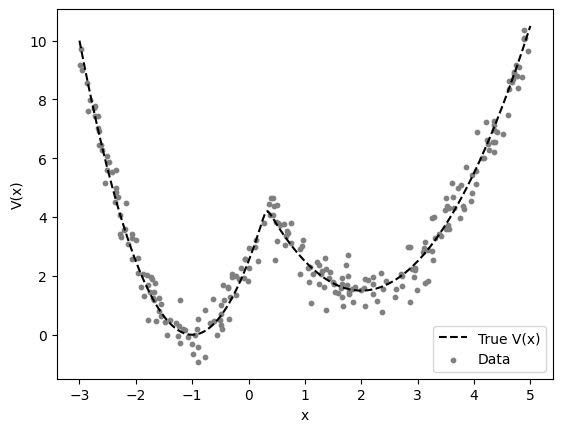

In [ ]:
torch.manual_seed(5)

def dw_pot(x, x1=-1, x2=2, k1=5, k2=2, alpha=5, deltaE=1.5):
	pot1 = 1/2 * k1 * (x - x1)**2
	pot2 = 1/2 * k2 * (x - x2)**2 + deltaE
	pot_tot = -1/alpha * torch.log(torch.exp(-alpha*pot1) + torch.exp(-alpha*pot2))
	return pot_tot

x_lin = torch.linspace(-3, 5, 200)
y_lin = dw_pot(x_lin)

xs = 8 * torch.rand(256) - 3
ys = dw_pot(xs) + 0.5 * torch.randn(256)

fig, ax = plt.subplots()
ax.plot(x_lin, y_lin, 'k--', label='True V(x)')
ax.scatter(xs, ys, color='grey', s=10, label='Data')
ax.legend()
ax.set_xlabel('x')
ax.set_ylabel('V(x)')

### DataLoader

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(xs.view(-1,1), ys.view(-1,1))
loader_full = DataLoader(dataset, batch_size=len(dataset), shuffle=True)
# if batch_size is not provided, it is set to 1
loader_64 = DataLoader(dataset, batch_size=64, shuffle=True)
loader_16 = DataLoader(dataset, batch_size=16, shuffle=True)
loader_4 = DataLoader(dataset, batch_size=4, shuffle=True)
for (x,y) in dataset:
	if y.item()==torch.inf:
		print('fuck')

In [ ]:
class NN(torch.nn.Module):
	def __init__(self):
		super().__init__()
		# input layer -> 1 hidden layer -> output layer
		self.net = torch.nn.Sequential(
			torch.nn.Linear(1, 32),
			torch.nn.SiLU(),
			torch.nn.Linear(32, 32),
			torch.nn.SiLU(),
			torch.nn.Linear(32, 1)
		)

	def forward(self, x):
		return self.net(x)

In [ ]:
def train_from_dataloader(model, loader, epochs=1000, lr=1e-3, weight_decay=0):
	optimizer = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay)
	loss_fn = torch.nn.MSELoss()
	X_all, Y_all = loader.dataset.tensors   # works for torch TensorDataset
	epoch_loss = []
	step_loss = []
	for epoch in range(epochs):
		train_loss = 0.0
		for xb, yb in loader: #run over batches
			y_pred = model(xb)
			loss = loss_fn(y_pred, yb)
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()
			train_loss += loss.item() * xb.size(0)
			with torch.no_grad():
				step_loss.append(loss_fn(model(X_all), Y_all).item())
		train_loss /= len(loader.dataset)
		epoch_loss.append(train_loss)
	return epoch_loss, step_loss

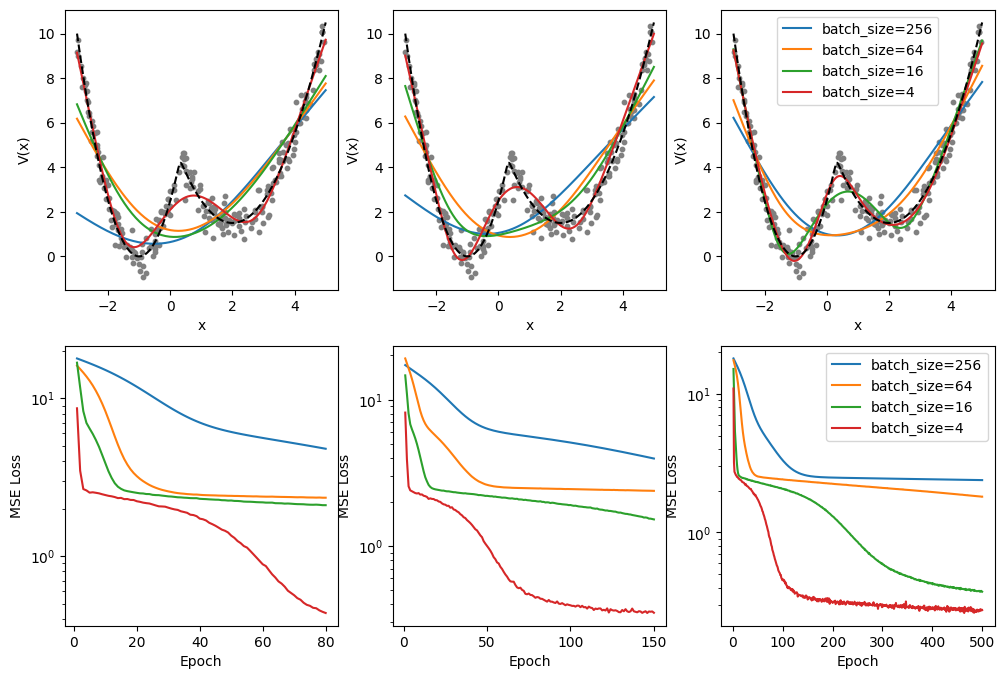

In [ ]:
fig, axes = plt.subplots(2,3, figsize=(12,8))

for col, epochs in enumerate([80, 150, 500]):
	for batch_size in [256, 64, 16, 4]:
		loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
		model = NN()
		MSEloss, _ = train_from_dataloader(model, loader, epochs, lr=1e-3)
		with torch.no_grad():
			axes[0, col].plot(x_lin.numpy(), model(x_lin.view(-1,1)).numpy(), label=f'{batch_size=}')
			axes[1, col].plot(torch.arange(1, epochs+1), MSEloss, label=f'{batch_size=}')
axes[0, -1].legend()
axes[1, -1].legend()
for ax in axes[0, :]:
	ax.plot(x_lin, y_lin, 'k--', label='True V(x)')
	ax.scatter(xs, ys, color='grey', s=10, label='Data')
	ax.set_xlabel('x')
	ax.set_ylabel('V(x)')
for ax in axes[1, :]:
	ax.set_xlabel('Epoch')
	ax.set_ylabel('MSE Loss')
	ax.set_yscale('log')

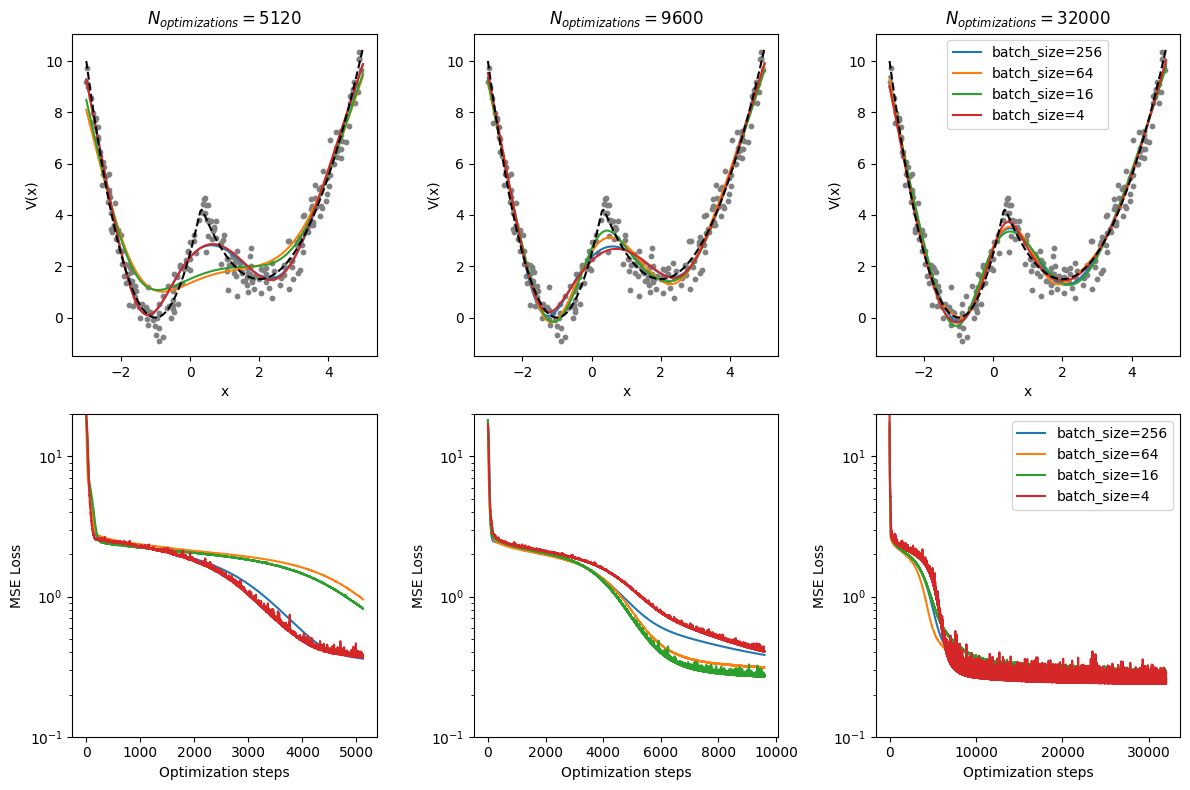

In [ ]:
fig, axes = plt.subplots(2,3, figsize=(12,8))

for col, epochs in enumerate([80, 150, 500]):
	for batch_size in [256, 64, 16, 4]:
		loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
		model = NN()
		normalized_epochs = epochs * int(batch_size/4)
		_, MSEloss = train_from_dataloader(model, loader, normalized_epochs, lr=1e-3, weight_decay=0.00) #NOTE 
		with torch.no_grad():
			axes[0, col].plot(x_lin.numpy(), model(x_lin.view(-1,1)).numpy(), label=f'{batch_size=}')
			axes[0, col].set_title(r'$N_{optimizations}=$'+f'{len(MSEloss)}')
			axes[1, col].plot(torch.arange(1, len(MSEloss)+1), MSEloss, label=f'{batch_size=}')
axes[0, -1].legend()
axes[1, -1].legend()
for ax in axes[0, :]:
	ax.plot(x_lin, y_lin, 'k--', label='True V(x)')
	ax.scatter(xs, ys, color='grey', s=10, label='Data')
	ax.set_xlabel('x')
	ax.set_ylabel('V(x)')
for ax in axes[1, :]:
	ax.set_xlabel('Optimization steps')
	ax.set_ylabel('MSE Loss')
	ax.set_yscale('log')
	ax.set_ylim(0.1, 20)
fig.tight_layout()

*Reflect*

A smaller batch size cuts the data into more batches. When training, a step is taken for every batch. Thus, more optimizations of the model parameters are done for smaller batch sizes. 

For the smaller mini-batches, every step involves fewer computations in the backward propagation but in turn yields very little information about the gradient. Therefore, the optimization steps are cheaper but results in noisier gradients.

A moderate batch size may provide a sweet spot between noisy gradients and cheap updates.

# W11B Early stopping

In [1]:
import torch
import matplotlib.pyplot as plt

### Data

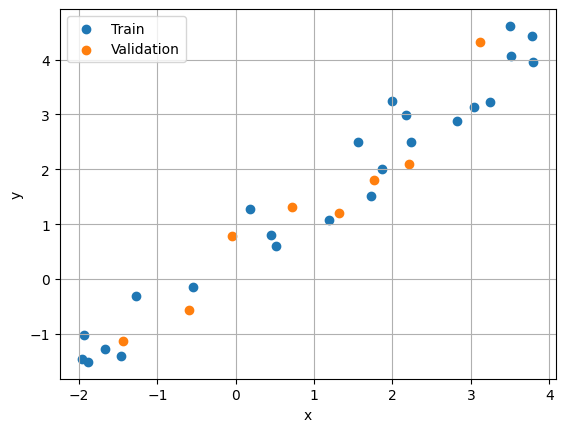

In [2]:
torch.manual_seed(69)

N = 32
xs = 6 * torch.rand(N) - 2
ys = xs + 0.5 + 0.5*torch.randn(N)

x_train = xs[0:24]
y_train = ys[0:24]
x_val = xs[24:]
y_val = ys[24:]

def plot_data(ax, xt, yt, xv, yv):
	ax.scatter(xt, yt, label='Train')
	ax.scatter(xv, yv, label='Validation')
	ax.legend()
	ax.grid()
	ax.set_xlabel('x')
	ax.set_ylabel('y')
fig, ax = plt.subplots()
plot_data(ax, x_train, y_train, x_val, y_val)

### Neural-network model

In [3]:
class NN(torch.nn.Module):
	def __init__(self):
		super().__init__()
		# input layer -> 1 hidden layer -> output layer
		self.net = torch.nn.Sequential(
			torch.nn.Linear(1, 8),
			torch.nn.SiLU(),
			torch.nn.Linear(8, 8),
			torch.nn.SiLU(),
			torch.nn.Linear(8, 8),
			torch.nn.SiLU(),
			torch.nn.Linear(8, 1)
		)

	def forward(self, x):
		x = x.view(-1,1)
		y = self.net(x)
		return y.flatten()

The model is intentionally more flexible than is needed to represent a straight line. This makes it
possible for prolonged training to fit details of the noise rather than only the underlying trend.

In [4]:
def train(model, x_train, y_train, x_val, y_val, epochs=1000, lr=1e-3, weight_decay=0.0):
	optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
	loss_fn = torch.nn.MSELoss()
	train_loss = []
	val_loss = []
	for epoch in range(epochs):
		y_pred = model(x_train)
		loss = loss_fn(y_pred, y_train)
		optimizer.zero_grad()
		loss.backward()
		optimizer.step()
		train_loss.append(loss.item())
		with torch.no_grad():
			val_loss.append(loss_fn(model(x_val), y_val).item())
	return train_loss, val_loss

### Prolonged training without regularization

In [8]:
model = NN()
train_loss, val_loss = train(model=model, 
							 x_train=x_train, y_train=y_train, 
							 x_val=x_val, y_val=y_val, 
							 lr=1e-3, epochs=30_000)

In [9]:
def plot_loss(ax, train_loss, val_loss):
	ax.plot(torch.arange(1, len(train_loss)+1), train_loss, label='Train loss')
	ax.plot(torch.arange(1, len(val_loss)+1), val_loss, label='Validation loss')
	ax.set_yscale('log')
	ax.set_xlabel('Epoch')
	ax.set_ylabel('MSE loss')
	ax.grid()
	ax.legend()

def plot_fit(ax, model, xmin, xmax):
	x_lin = torch.linspace(xmin, xmax, 200)
	with torch.no_grad():
		ax.plot(x_lin, model(x_lin), label='Fit')
		ax.legend(loc='upper left')

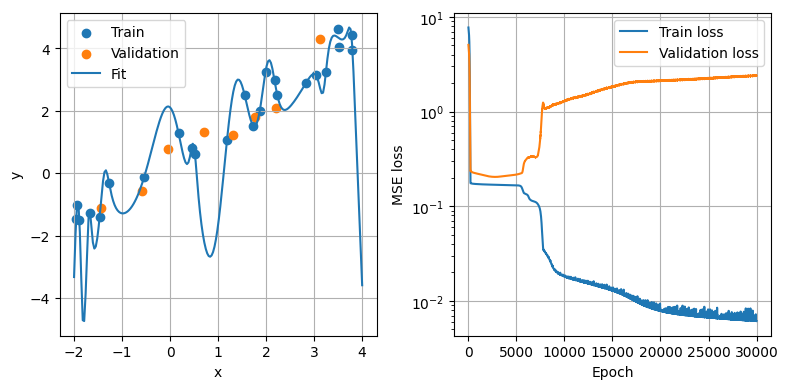

In [10]:
fig, axes = plt.subplots(1,2, figsize=(8,4))
plot_data(axes[0], x_train, y_train, x_val, y_val)
plot_loss(axes[1], train_loss, val_loss)
plot_fit(axes[0], model, xmin=-2, xmax=4)
fig.tight_layout()

The training loss is allowed to keep decreasing, since that is the loss function we are minimizing. The validation loss is simply being evaluated but not acted upon.

The fit follows the noise of the training set rather than the underlying trend, so it has overfitted the data.

The best fit is not necessarily the one with lowest training loss. We see that this model has very high validation loss, meaning that on new data, the model would predict very poorly. Thus it is not a good model for predicting on new data.

### Weight decay

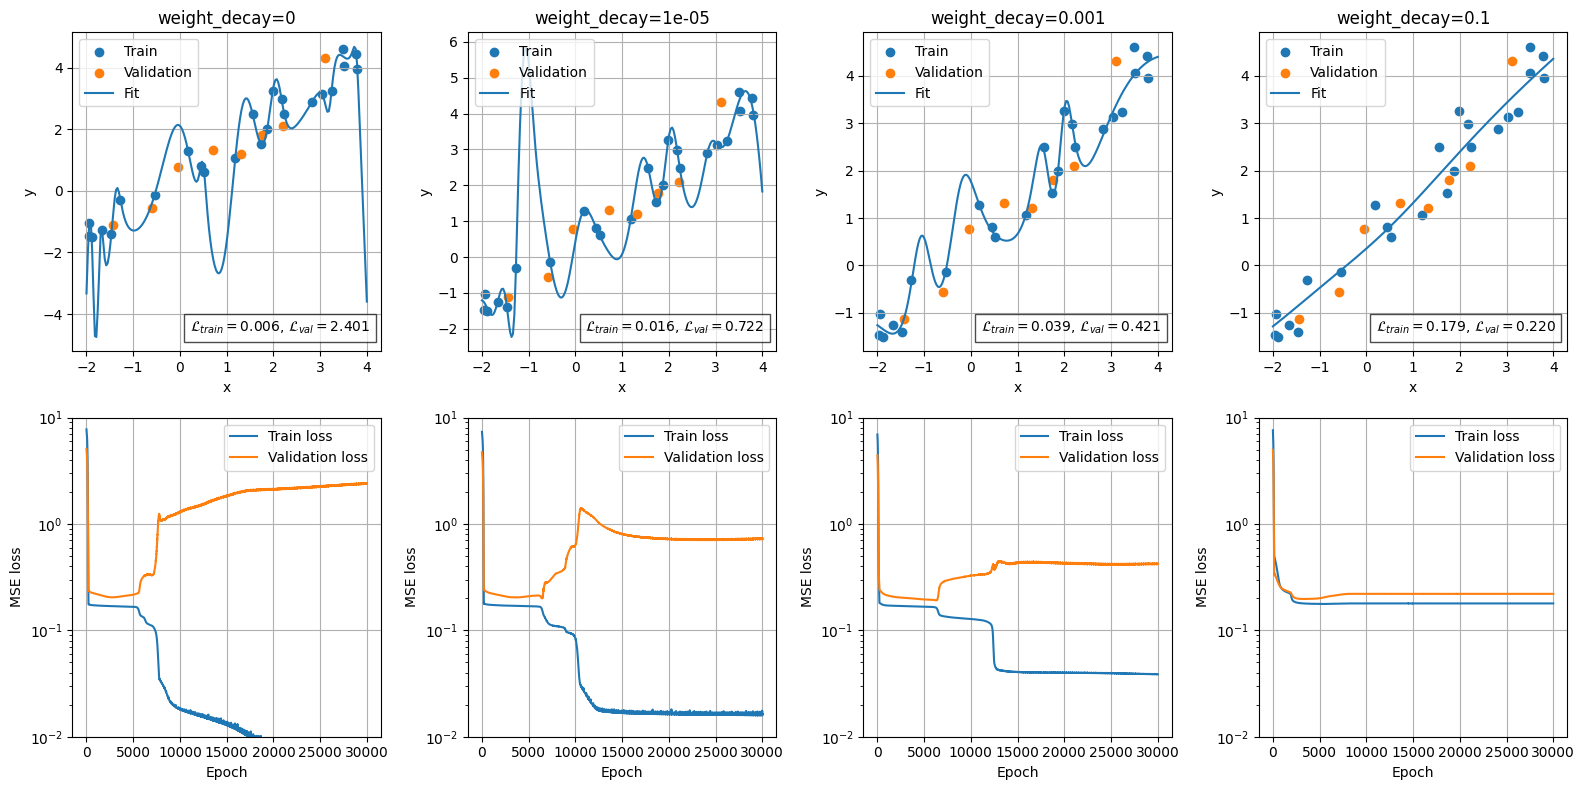

In [ ]:
fig, axes = plt.subplots(2,4, figsize=(16,8))
axes
for col, weight_decay in enumerate([0, 1e-5, 1e-3, 1e-1]):
	model = NN()
	train_loss, val_loss = train(model=model, 
							 x_train=x_train, y_train=y_train, 
							 x_val=x_val, y_val=y_val, 
							 lr=1e-3, epochs=30_000, weight_decay=weight_decay)
	plot_data(axes[0, col], x_train, y_train, x_val, y_val)
	plot_loss(axes[1, col], train_loss, val_loss)
	plot_fit(axes[0, col], model, xmin=-2, xmax=4)
	axes[0, col].text(0.38, 0.10, 
					  r'$\mathcal{L}_{train}=$'+f'{train_loss[-1]:.3f}, ' + 
					  r'$\mathcal{L}_{val}=$'+f'{val_loss[-1]:.3f}',
					  transform=axes[0, col].transAxes, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))
	axes[0, col].set_title(f'{weight_decay=}')
	axes[1, col].set_ylim(1e-2, 10)
fig.tight_layout()



*Explain the trade-off*

Notice how the increased weight decay (regularization) reveals the underlying linear function, which in turn reduces the validation loss at the cost of higher training loss. Too small weight decay allows the model to fit the noise (which is bad), while too large weight decay will deter the model from learning anything (very small weights, very small optimization steps). There is a sweet spot in between, and it seems for my case to be around 0.1.

### Early stopping

In [5]:
import copy

class EarlyStopping:
	def __init__(self , patience=20):
		# Number of epochs to wait after the last  improvement
		self.patience = patience
		self.best_loss  = None
		self.best_state  = None
		self.best_epoch  = None
		self.counter = 0
		self.early_stop  = False

	def __call__(self, val_loss, model=None, epoch=None):
		if self.best_loss is None or val_loss < self.best_loss:
			self.best_loss  = val_loss
			self.counter = 0
			if epoch is not None:
				self.best_epoch = epoch
			if model is not None:
				self.best_state = copy.deepcopy(model.state_dict())
		else:
			self.counter += 1
			if self.counter >= self.patience:
				self.early_stop = True

In [6]:
def train_early_stopping(model, early_stopping, x_train, y_train, x_val, y_val, epochs=1000, lr=1e-3, weight_decay=0.0):
	optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
	loss_fn = torch.nn.MSELoss()
	train_loss = []
	val_loss = []
	for epoch in range(epochs):
		y_pred = model(x_train)
		loss = loss_fn(y_pred, y_train)
		optimizer.zero_grad()
		loss.backward()
		optimizer.step()
		train_loss.append(loss.item())
		with torch.no_grad():
			_val_loss = loss_fn(model(x_val), y_val).item()
			val_loss.append(_val_loss)
		early_stopping(_val_loss, model, epoch)
		if early_stopping.early_stop:
			break
	return train_loss, val_loss

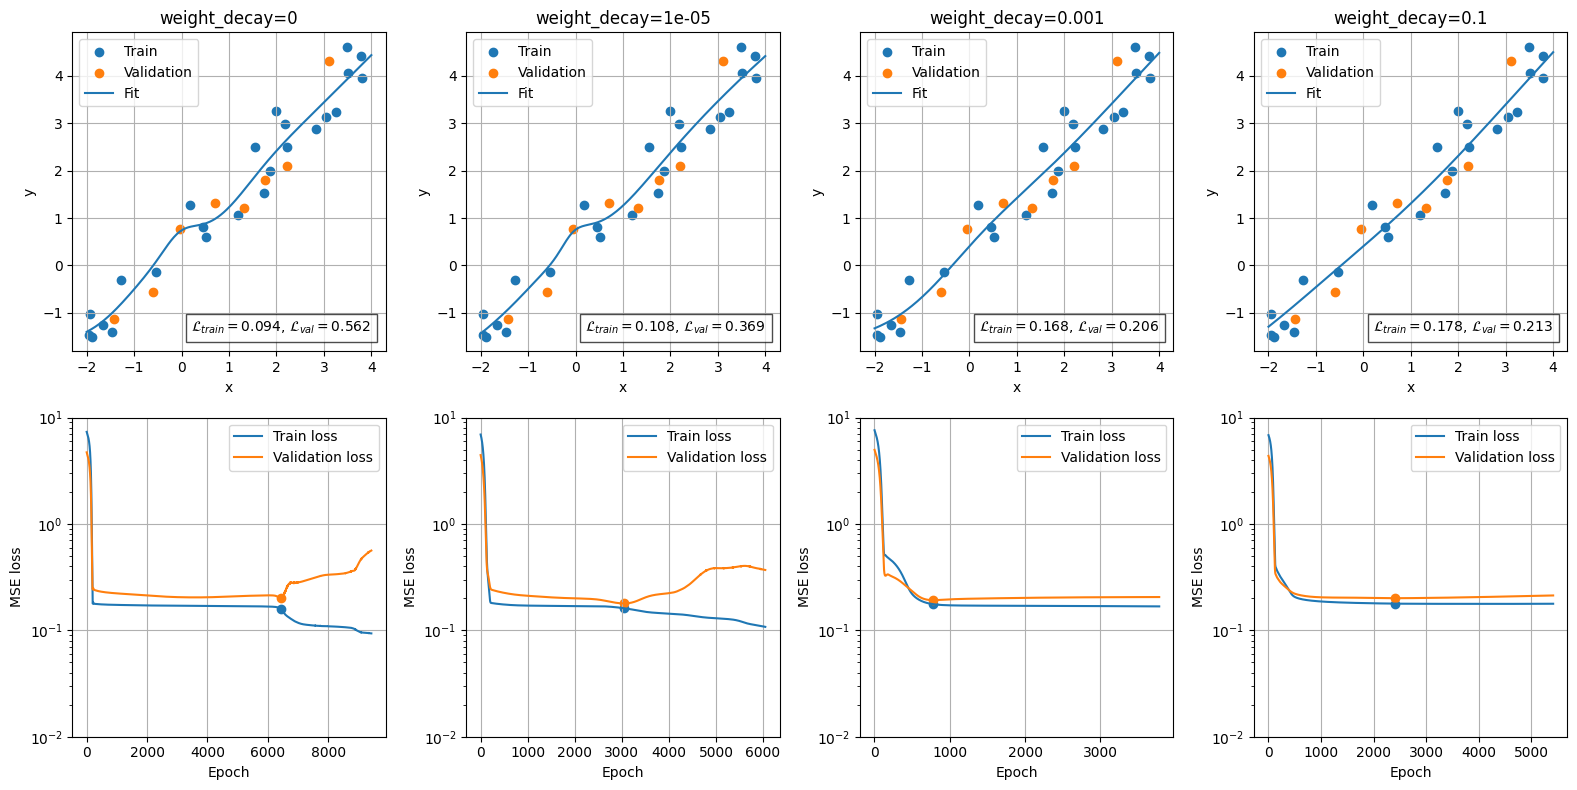

In [11]:
fig, axes = plt.subplots(2,4, figsize=(16,8))
axes
for col, weight_decay in enumerate([0, 1e-5, 1e-3, 1e-1]):
	model = NN()
	early_stopping = EarlyStopping(patience=3000)
	train_loss, val_loss = train_early_stopping(model=model, early_stopping=early_stopping,
												x_train=x_train, y_train=y_train, 
												x_val=x_val, y_val=y_val, 
												lr=1e-3, epochs=30_000, weight_decay=weight_decay)
	model.load_state_dict(early_stopping.best_state)
	plot_data(axes[0, col], x_train, y_train, x_val, y_val)
	plot_loss(axes[1, col], train_loss, val_loss)
	plot_fit(axes[0, col], model, xmin=-2, xmax=4)
	axes[0, col].text(0.38, 0.10, 
					  r'$\mathcal{L}_{train}=$'+f'{train_loss[-1]:.3f}, ' + 
					  r'$\mathcal{L}_{val}=$'+f'{val_loss[-1]:.3f}',
					  transform=axes[0, col].transAxes, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7))
	axes[0, col].set_title(f'{weight_decay=}')
	axes[1, col].set_ylim(1e-2, 10)
	best_model_epoch = early_stopping.best_epoch
	axes[1, col].scatter(best_model_epoch, train_loss[best_model_epoch], c='C0') # NOTE: starts at 0, not 1
	axes[1, col].scatter(best_model_epoch, val_loss[best_model_epoch], c='C1')
fig.tight_layout()



When training loss decreases and validation loss increases, it indicates overfitting, and picking the best model just before this point (of no return) stops overfitting.

A combination of weight decay and early stopping may still give the best validation loss, since we still want to discourage large parameters. This cannot be done by early stopping. With weight decay we are also required to find a "good" parameter, which is not something we need to worry about with early stopping.

If patience is too small, fluctuations in validation loss, which is normal during training, would lead to early stopping when the model is still learning the function. Too large patience means using unecessary amounts of computational resources.

If we used a seperate test set to determine weight decay or patience, we would indirectly introduce model bias towards the test set. Thus the test set cannot provide an estimate of how well the model generalizes to unseen data.

Early stopping limits how closely the network can adapt to the finite training sample, even though no explicit penalty is added to the loss function.

# W11C Fitting a pair potential via total energies

In [12]:
import torch
import numpy as np
import matplotlib.pyplot as plt

In [13]:
class AtomicCluster(torch.nn.Module):
	def __init__(self, calc, Natoms =7, pos=None,  reference_energy =0.):
		super().__init__()
		self.calc = calc
		self.reference_energy = torch.tensor(float(reference_energy), dtype=torch.float32)
		if pos is None:
			pos = 0.75*torch.randn(Natoms, 2)
		elif not isinstance(pos, torch.Tensor):
			pos = torch.tensor(pos, dtype=torch.float32)
		self.positions = torch.nn.Parameter(pos)
		self.N = len(pos)
		
	@torch.no_grad()
	def copy(self):
		pos = self.positions.clone()
		return self.__class__(self.calc, pos=pos)
	
	def forward(self):
		if self.calc is None:
			return self.reference_energy
		r = torch.pdist(self.positions) # torch version of scipy.spatial.distance.pdist
		mask = r < 2.0
		r_short = r[mask]
		return torch.sum(self.calc(r_short))
	
	@torch.no_grad()
	def draw(self, ax):
		thetas = np.linspace(0, 2*np.pi, 100)
		for data in self.positions.numpy():
			ax.fill(data[0]+0.5* np.cos(thetas),
					data[1]+0.5* np.sin(thetas), facecolor ='C0', edgecolor='k', alpha =0.5)
		for i in range(self.positions.data.shape[0]):
			ax.text(self.positions.data[i, 0],
					self.positions.data[i, 1], f'{i}', color='w', ha='center', va='center')

In [14]:
from torch.utils.data import Dataset, DataLoader

class  AtomicClusterDataset(Dataset):
	def __init__(self, filename, N_max=200):
		data = np.loadtxt(filename)[: N_max]
		N = (data.shape[1] - 1) // 2
		self.positions = data[:, :2*N].reshape(-1,N,2)
		self.labels = data[:,-1]
	def __len__(self):
		return len(self.labels)
	def  __getitem__(self, idx):
		positions = torch.tensor(self.positions[idx], dtype=torch.float32)
		label = torch.tensor(self.labels[idx], dtype=torch.float32)
		return positions, label

# Load atomic positions and energies for 5 unrelaxed atomic clusters
dataset = AtomicClusterDataset('pos_14_ene_1_1000.txt', N_max=5)
loader = DataLoader(dataset=dataset, batch_size=16, shuffle=False)

atomic_clusters = []
for positions, energies in loader:
	for pos, e in zip(positions, energies):
		atomic_cluster = AtomicCluster(None, pos=pos, reference_energy=e)
		atomic_clusters.append(atomic_cluster)

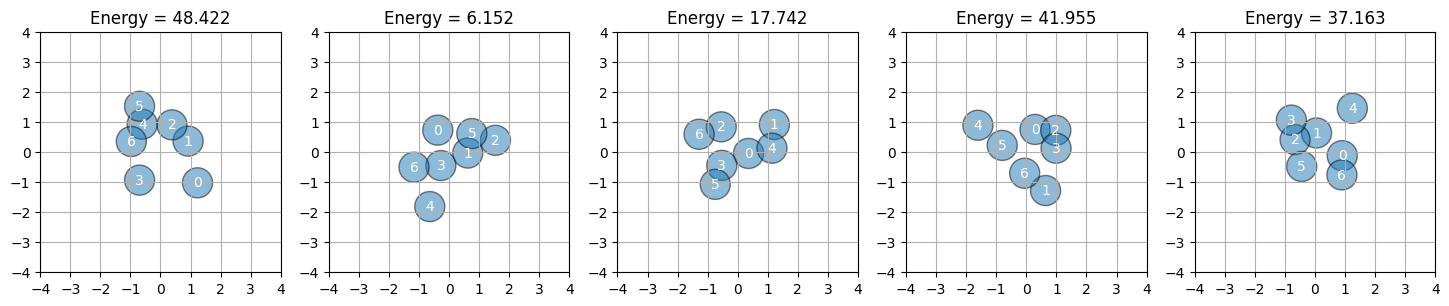

In [15]:
fig, axes = plt.subplots(1,5, figsize=(18,4))

for ax, ac in zip(axes, atomic_clusters):
	ac.draw(ax)
	ax.set_title(f'Energy = {ac.reference_energy.item():.3f}')
	ax.set_xlim(-4, 4)
	ax.set_ylim(-4, 4)
	ax.set_aspect('equal')
	ax.set_xticks(np.arange(-4,4+1))
	ax.grid()

### Train a NN pair-potential

In [ ]:
class NNPairPotential(torch.nn.Module):
	def __init__(self, hidden_dim=128):
		super().__init__()
		self.net = torch.nn.Sequential(
			torch.nn.Linear(1, hidden_dim),
			torch.nn.SiLU(),	# 1 hidden layer + SiLU
			torch.nn.Linear(hidden_dim, hidden_dim),
			torch.nn.SiLU(),	# 2 hidden layer + SiLU
			torch.nn.Linear(hidden_dim, hidden_dim),
			torch.nn.SiLU(),	# 3 hidden layer + SiLU
			torch.nn.Linear(hidden_dim, 1),
		)
	def forward(self, r):
		return self.net(r.unsqueeze(-1)).squeeze(-1)

def parity_plot(ax, y_train, y_pred, epoch, lr):
	ax.scatter(y_train, y_pred, alpha=0.5)
	ax.set_title(f'{epoch} epochs, lr = {lr}')
	ax.set_ylabel('Prediction')
	ax.set_xlabel('Target')

def cluster_energy(model, pos, cutoff=2.0):
	r = torch.pdist(pos)
	return model(r[r < cutoff]).sum()

def train_batch_parityplot(model, loader, axes, epochs=1000, lr=1e-3, weight_decay=0):
	optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
	X_all = torch.stack([loader.dataset[i][0] for i in range(len(loader.dataset))])
	Y_all = torch.stack([loader.dataset[i][1] for i in range(len(loader.dataset))])
	ax_idx = 0
	for epoch in range(epochs):
		model.train()
		train_loss = 0.0
		for xb, yb in loader: #run over batches
			potNN = torch.stack([cluster_energy(model, pos=p) for p in xb])
			# model returns potential energy per atom so we take the sum
			loss = torch.mean((yb - potNN)**2)
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()
			train_loss += loss.item() * xb.size(0)
		train_loss /= len(loader.dataset)
		if (epoch+1) % 100 == 0 or epoch == 0:
			print(f'{epoch if epoch==0 else epoch+1}: Loss =', train_loss)
		if (epoch+1) in [2, 10, 100, 2000]:
			model.eval()
			with torch.no_grad():
				pred = torch.stack([cluster_energy(model, pos=p) for p in X_all])
				parity_plot(axes[ax_idx], Y_all, pred, (epoch+1), lr)
				ax_idx += 1


I found that a wide network made it easier to find the true potential (the extra dip)

With just 2 hidden layers, it was more difficult to find the potential.

With 4 hidden layers, gradients are smaller but seems to get closer to the true potential

3 hidden layers is a good middle ground.

Perhaps a smaller learning rate and more epochs would be benefitial.

0: Loss = 356.8010055541992
100: Loss = 0.9824853909015655
200: Loss = 0.5229665660858154
300: Loss = 0.4484635730087757
400: Loss = 0.4005448231101036
500: Loss = 0.36393470644950865
600: Loss = 0.3266333117336035
700: Loss = 0.28264269277453424
800: Loss = 0.22692626230418683
900: Loss = 0.06718036565929651
1000: Loss = 0.061673453561961654
1100: Loss = 0.023668538630008697
1200: Loss = 0.08642988167703151
1300: Loss = 0.011533002126961947
1400: Loss = 0.014606222305446863
1500: Loss = 0.008734233304858207
1600: Loss = 0.017926385453902186
1700: Loss = 0.02835814298130572
1800: Loss = 0.01502881096675992
1900: Loss = 0.0772494800016284
2000: Loss = 0.010438602529466151


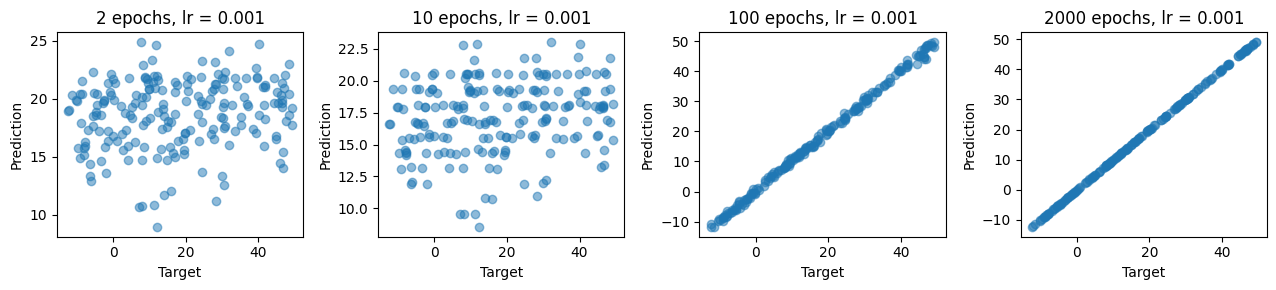

In [45]:
dataset = AtomicClusterDataset('pos_14_ene_1_1000.txt', N_max=200)  
loader = DataLoader(dataset=dataset, batch_size=8, shuffle=False)

fig, axes = plt.subplots(1,4, figsize=(13,3))
model = NNPairPotential()
train_batch_parityplot(model, loader, axes, epochs=2000)
fig.tight_layout()

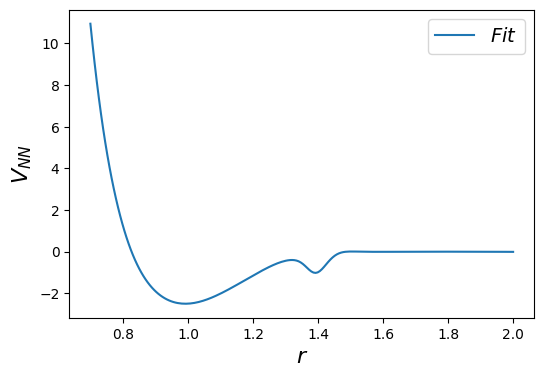

In [48]:
fig, ax = plt.subplots(figsize=(6,4))

r = torch.linspace(0.7, 2.0, 200)
model.eval()
with torch.no_grad():
	pred = model(r)
	ax.plot(r, pred, label=r'$Fit$')
	ax.set_xlabel(r'$r$', fontsize=16)
	ax.set_ylabel(r'$V_{NN}$', fontsize=16)
	ax.legend(fontsize=14)

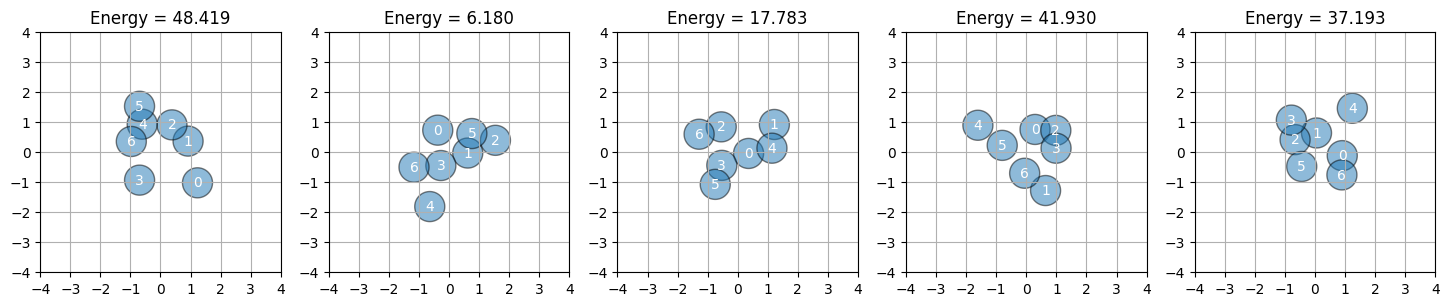

In [35]:
fig, axes = plt.subplots(1,5, figsize=(18,4))

nn_atomic_clusters = []
for positions, energies in loader:
	for pos, e in zip(positions, energies):
		atomic_cluster = AtomicCluster(model, pos=pos)
		nn_atomic_clusters.append(atomic_cluster)

for ax, ac in zip(axes, nn_atomic_clusters[:5]):
	ac.draw(ax)
	ax.set_title(f'Energy = {ac():.3f}')
	ax.set_xlim(-4, 4)
	ax.set_ylim(-4, 4)
	ax.set_aspect('equal')
	ax.set_xticks(np.arange(-4,4+1))
	ax.grid()

Pretty close to the original

### Relaxation

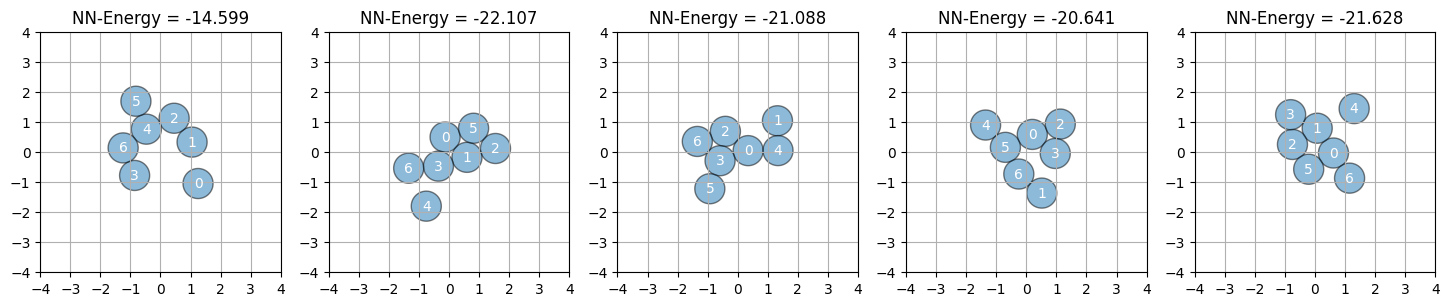

In [46]:
for p in model.parameters():
	p.requires_grad = False

relaxed_atomic_clusters = []
for positions, energies in loader:
	for pos, e in zip(positions, energies):
		pos = pos.clone().requires_grad_(True)
		# optimizer expects an iterable, therefore pass pos as list
		optimizer = torch.optim.Adam([pos], lr=1e-2)
		for step in range(500):
			energy = cluster_energy(model, pos)
			loss = energy
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()
		atomic_cluster = AtomicCluster(model, pos=pos)
		relaxed_atomic_clusters.append(atomic_cluster)

fig, axes = plt.subplots(1,5, figsize=(18,4))
for ax, ac in zip(axes, relaxed_atomic_clusters[:5]):
	ac.draw(ax)
	ax.set_title(f'NN-Energy = {ac():.3f}')
	ax.set_xlim(-4, 4)
	ax.set_ylim(-4, 4)
	ax.set_aspect('equal')
	ax.set_xticks(np.arange(-4,4+1))
	ax.grid()

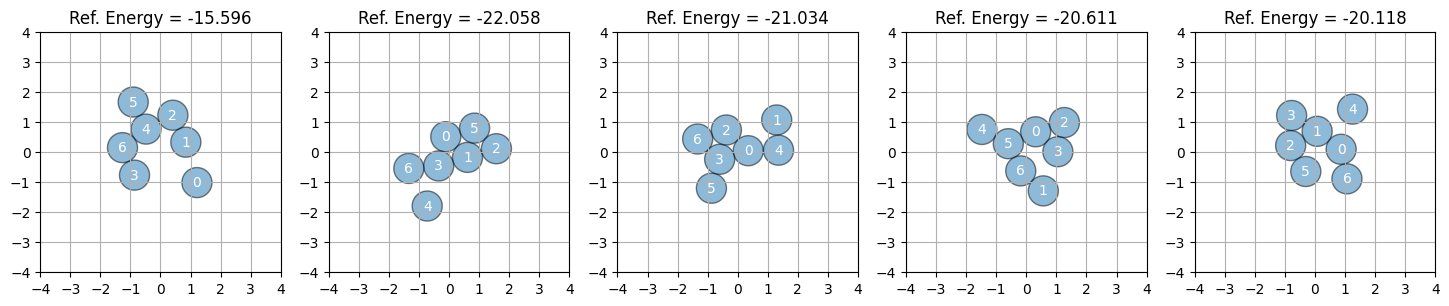

In [53]:
# Load atomic positions and energies for 5 unrelaxed atomic clusters
relaxed_dataset = AtomicClusterDataset('pos_14_ene_1_1000_relaxed.txt', N_max=5)
relaxed_loader = DataLoader(dataset=relaxed_dataset, batch_size=16, shuffle=False)

ref_relaxed_atomic_clusters = []
for positions, energies in relaxed_loader:
	for pos, e in zip(positions, energies):
		atomic_cluster = AtomicCluster(model, pos=pos)
		ref_relaxed_atomic_clusters.append(atomic_cluster)

fig, axes = plt.subplots(1,5, figsize=(18,4))
for ax, ac in zip(axes, ref_relaxed_atomic_clusters[:5]):
	ac.draw(ax)
	ax.set_title(f'Ref. Energy = {ac():.3f}')
	ax.set_xlim(-4, 4)
	ax.set_ylim(-4, 4)
	ax.set_aspect('equal')
	ax.set_xticks(np.arange(-4,4+1))
	ax.grid()

Comparing the relaxed energies with a reference figure, some energies are off by a few units of energy, although the neural network learned the potential very well. The network trained on learning energies of 200 clusters. During optimization, clusters that may not have been represented in the training set are introduced, and the model has to predict on this unseen data, whcih has some amount of error.

If we used the database of relaxed structures to fit the potential, we would have explored even less of the potential energy landscape - we would've only looked into the main basin of attraction, and not what happens when clusters are shuffled. Thus relaxation would've been even more difficult.

### Best possible structures

tensor(0.0841)
Initial: 48.505371, Best: -15.524393, Steps: 1000
tensor(0.1102)
Initial: 6.179409, Best: -21.965466, Steps: 1000
tensor(0.0110)
Initial: 17.822178, Best: -20.945850, Steps: 1000
tensor(0.0015)
Initial: 42.056694, Best: -20.472050, Steps: 1000
tensor(0.0004)
Initial: 37.163242, Best: -20.047758, Steps: 285
tensor(0.0477)
Initial: 15.813993, Best: -19.923038, Steps: 1000
tensor(0.0286)
Initial: 34.196495, Best: -25.923552, Steps: 183
tensor(0.0006)
Initial: -0.115496, Best: -23.426250, Steps: 509
tensor(0.0475)
Initial: 24.710228, Best: -18.002573, Steps: 678
tensor(0.0007)
Initial: -7.975110, Best: -19.501888, Steps: 876
tensor(0.0003)
Initial: 17.024223, Best: -25.451147, Steps: 383
tensor(0.0001)
Initial: 30.952490, Best: -21.475033, Steps: 429
tensor(0.0121)
Initial: 41.694653, Best: -19.012159, Steps: 1000
tensor(0.0738)
Initial: 46.490963, Best: -20.960114, Steps: 218
tensor(5.6854e-05)
Initial: -8.926567, Best: -25.916565, Steps: 289
tensor(0.0227)
Initial: 35.3718

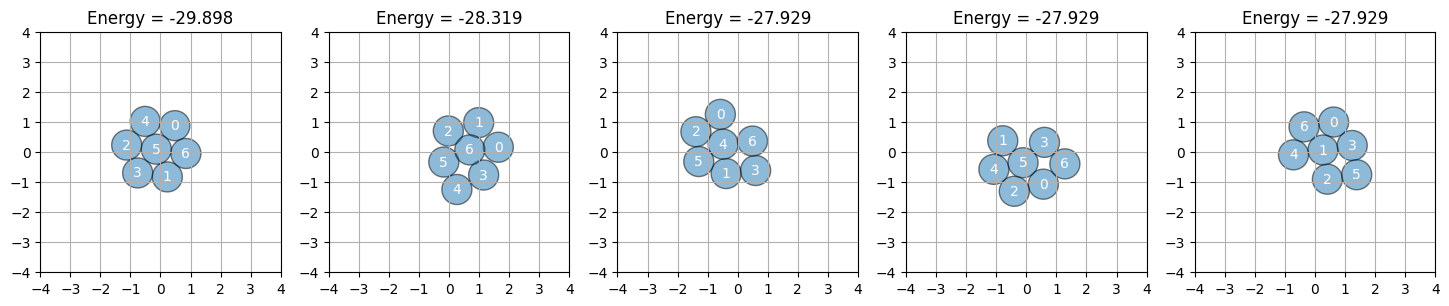

In [ ]:
import copy

class EarlyStopping:
	def __init__(self , patience=20):
		# Number of epochs to wait after the last  improvement
		self.patience = patience
		self.best_loss  = None
		self.best_state  = None
		self.best_epoch  = None
		self.counter = 0
		self.early_stop  = False

	def __call__(self, val_loss, model=None, pos=None, epoch=None):
		assert (model is None) != (pos is None), \
			"Provide either model or pos, but not both."

		if self.best_loss is None or val_loss < self.best_loss:
			self.best_loss  = val_loss
			self.counter = 0
			if epoch is not None:
				self.best_epoch = epoch
			if pos is not None:
				self.best_state = pos.detach().clone()
			if model is not None:
				self.best_state = copy.deepcopy(model.state_dict())
		else:
			self.counter += 1
			if self.counter >= self.patience:
				self.early_stop = True

dataset = AtomicClusterDataset('pos_14_ene_1_1000.txt', N_max=1000)  

best_atomic_clusters = []
for pos, e in dataset:
	early_stopping = EarlyStopping(patience=100)
	pos = pos.clone().requires_grad_(True)
	initial_pos = pos.detach().clone()
	# optimizer expects an iterable, therefore pass pos as list
	optimizer = torch.optim.Adam([pos], lr=1e-2)
	for step in range(1000):
		energy = cluster_energy(model, pos)
		loss = energy
		early_stopping(loss.item(), pos=pos, epoch=step)
		if early_stopping.early_stop:
			break
		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

	best_pos = early_stopping.best_state
	print(pos.grad.norm())
	print(
		f"Initial: {cluster_energy(model, initial_pos).item():.6f}, "
		f"Best: {cluster_energy(model, best_pos).item():.6f}, "
		f"Steps: {step+1}"
	)

	atomic_cluster = AtomicCluster(model, pos=early_stopping.best_state)
	best_atomic_clusters.append((atomic_cluster, cluster_energy(model, best_pos).item()))

best_atomic_clusters.sort(key=lambda x: x[1])
acs, _ = zip(*best_atomic_clusters)
fig, axes = plt.subplots(1,5, figsize=(18,4))
for ax, ac in zip(axes, acs):
	ac.draw(ax)
	ax.set_title(f'Energy = {ac():.3f}')
	ax.set_xlim(-4, 4)
	ax.set_ylim(-4, 4)
	ax.set_aspect('equal')
	ax.set_xticks(np.arange(-4,4+1))
	ax.grid()

# W11D Learning trajectories for particles interacting through a Morse potential


In [1]:
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import numpy as np

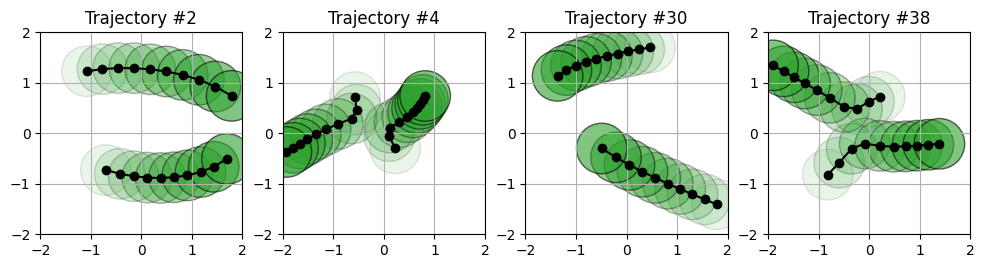

In [10]:
loaded = np.load("trajectories.npz")
data = loaded["trajectories"].astype(np.float32)

Ntrajectories = data.shape[0]
Ntimes = data.shape[1]

def plot_traj(ax, data, index):
	x1 = data[index][:, 0]
	y1 = data[index][:, 1]
	x2 = data[index][:, 2]
	y2 = data[index][:, 3]

	ax.plot(x1, y1, c='k', marker='o')
	ax.plot(x2, y2, c='k', marker='o')
	for i, alpha in enumerate(np.linspace(0.1, 0.6, 10)):
		circle1 = Circle([x1[i], y1[i]], radius=0.5, alpha=alpha, facecolor='C2')
		circle1_edge = Circle([x1[i], y1[i]], radius=0.5, edgecolor='k', fill=False, alpha=alpha)
		ax.add_patch(circle1)
		ax.add_patch(circle1_edge)
		circle2 = Circle([x2[i], y2[i]], radius=0.5, alpha=alpha, facecolor='C2')
		circle2_edge = Circle([x2[i], y2[i]], radius=0.5, edgecolor='k', fill=False, alpha=alpha)
		ax.add_patch(circle2)
		ax.add_patch(circle2_edge)
		
	ax.set_xlim(-2, 2)
	ax.set_ylim(-2, 2)
	ax.set_xticks(np.arange(-2,2+1))
	ax.set_yticks(np.arange(-2,2+1))
	ax.set_aspect('equal')
	ax.set_title(f'Trajectory #{index}')
	ax.grid()

fig, axes = plt.subplots(1,4, figsize=(12,3))
for ax, index in zip(axes, [2, 4, 30, 38]):
	plot_traj(ax, data, index)
	

### A dataset of short trajectory pieces

The following code takes a trajectory and turns it into a dataset.

Say a trajectory has 10 positions and we want a window length of 3. The window length means how many positions will the NN see (training data) before predicting the next move. So it will see 3 consecutive positions as training data and the following position as target prediction. Then from 10 trajectories we can make 10-3=7 "data points".

440986
len(dataset) == 7*data: True
torch.Size([12]) torch.Size([4])


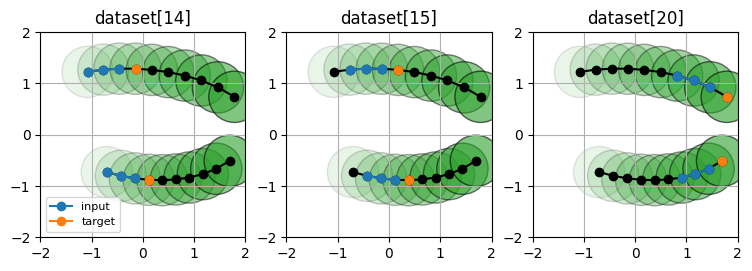

In [11]:
from torch.utils.data import Dataset, DataLoader
class TrajectoryDataset(Dataset):
	def __init__(self, trajectories, window_length=3):
		self.trajectories = torch.as_tensor(trajectories, dtype=torch.float32)
		self.window_length = window_length
		self.Ntrajectories = self.trajectories.shape[0]
		self.Ntimes = self.trajectories.shape[1]
		self.Npieces_per_trajectory = self.Ntimes - self.window_length

	def __len__(self):
		return self.Ntrajectories * self.Npieces_per_trajectory
	
	def __getitem__(self, index):
		# Determine which complete trajectory this item uses
		trajectory_index = index // self.Npieces_per_trajectory
		# Determine the starting time within that trajectory
		start = index % self.Npieces_per_trajectory
		stop = start + self.window_length
		trajectory = self.trajectories[trajectory_index] # shape = 10,4
		X = trajectory[start:stop].reshape(-1) # shape = 3,4 -> 12
		Y = trajectory[stop] # shape = 4
		return X, Y

dataset = TrajectoryDataset(data)
print(len(dataset))
print('len(dataset) == 7*data:', len(dataset) == 7 * len(data))
X, Y = dataset[0]
print(X.shape, Y.shape)


def plot_XY(ax, dataset, index):
	X, Y = dataset[index]
	X = X.reshape(3, 4)  # shape as matrix to easily collect coordinates
	x1 = X[:, 0]
	y1 = X[:, 1]
	x2 = X[:, 2]
	y2 = X[:, 3]

	x1_target = Y[0]
	y1_target = Y[1]
	x2_target = Y[2]
	y2_target = Y[3]

	ax.plot(x1, y1, c='C0', marker='o', label='input')
	ax.plot(x2, y2, c='C0', marker='o')
	ax.plot(x1_target, y1_target, c='C1', marker='o', label='target')
	ax.plot(x2_target, y2_target, c='C1', marker='o')

	ax.set_title(f'dataset[{index}]')

fig, axes = plt.subplots(1,3, figsize=(9,3))
for ax, index in zip(axes, [14, 15, 20]):
	plot_traj(ax, data, index=2)
	plot_XY(ax, dataset, index)
axes[0].legend(loc='lower left', fontsize=8)

### Shuffled mini-batches

In [12]:
loader = DataLoader(dataset, batch_size=64, shuffle=True)

for xb, yb in loader:
	print(xb.shape)
	print(yb.shape)
	break

torch.Size([64, 12])
torch.Size([64, 4])


Shuffling in the loader takes the pairs of X and Y and redistribute them randomly. Thus, the input is never seperated from its target. Similarly, the ordering inside a single window remains intact, since that is subject to the shape of X. The shuffling will, however, change the order of all short trajectory pieces. So 10 small trajectory pieces from one trajectory will no longer be presented in order. Therefore the first 7 examples will most likely not belong the same original trajectory.

### Training, validation, and test trajectories

It is important here that short trajectory pieces from one complete trajectory are not present in several sets. For a single trajectory, all subsequent small trajectories are strongly related, i.e. share many of the same positions. Thus splitting all small trajectories into three sets may introduce overlapping, where data look very similar. This yields biased predictions, and we would see an artificially good prediction on the validation and test set.

So short trajectory pieces from a complete trajectory should be restricted to one set. Therefore, we split the complete trajectories into train, validation, and test trajectories, before making short trajectory pieces.

In [13]:
# I don't condone this splitting, but assuming the trajectories are 
# given in an uncorrelated order, it is fine
train_traj = data[:800]
val_traj = data[800:900]
test_traj = data[900:1000]

train_dataset = TrajectoryDataset(train_traj)
val_dataset = TrajectoryDataset(val_traj)
test_dataset = TrajectoryDataset(test_traj)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, shuffle=False)
test_loader = DataLoader(test_dataset, shuffle=False)

### A model for one-step predictions

In [14]:
class OneStepTrajectoryNN(torch.nn.Module):
	def __init__(self):
		super().__init__()
		self.net = torch.nn.Sequential(
			torch.nn.Linear(12, 64),  	# input + hidden layer 1
			torch.nn.SiLU(),			# hidden layer 1 activation
			torch.nn.Linear(64, 64),	# hidden layer 2
			torch.nn.SiLU(),			# hidden layer 2 activation
			torch.nn.Linear(64, 64),	# hidden layer 3
			torch.nn.SiLU(),			# hidden layer 3 activation
			torch.nn.Linear(64, 4)		# output layer
		)

	def forward(self, x):
		return self.net(x)

In [15]:
def train_from_dataloader(model, early_stopping, train_loader, val_loader, test_loader, epochs=1000, lr=1e-3, weight_decay=0):
	optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
	loss_fn = torch.nn.MSELoss()
	train_loss = []
	val_loss = []

	for epoch in range(epochs):
		### Training ###
		model.train()
		_train_loss = 0.0
		for xb, yb in train_loader: #run over batches
			y_pred = model(xb)
			loss = loss_fn(y_pred, yb)
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()
			_train_loss += loss.item() * xb.size(0)
		_train_loss /= len(train_loader.dataset)
		train_loss.append(_train_loss)

		### Validation ###
		model.eval()
		with torch.no_grad():
			_val_loss = 0.0
			for x, y in val_loader:
				_val_loss += loss_fn(model(x), y).item() * x.size(0)
			_val_loss /= len(val_loader.dataset)
			val_loss.append(_val_loss)
		early_stopping(_val_loss, model, epoch)
		if early_stopping.early_stop:
			### Test ###
			with torch.no_grad():
				_test_loss = 0.0
				for x, y in test_loader:
					_test_loss += loss_fn(model(x), y).item() * x.size(0)
				_test_loss /= len(test_loader.dataset)
				test_loss = _test_loss
			break

	
	return train_loss, val_loss, test_loss

In [16]:
import copy

class EarlyStopping:
	def __init__(self , patience=20):
		# Number of epochs to wait after the last  improvement
		self.patience = patience
		self.best_loss  = None
		self.best_state  = None
		self.best_epoch  = None
		self.counter = 0
		self.early_stop  = False

	def __call__(self, val_loss, model=None, epoch=None):
		if self.best_loss is None or val_loss < self.best_loss:
			self.best_loss  = val_loss
			self.counter = 0
			if epoch is not None:
				self.best_epoch = epoch
			if model is not None:
				self.best_state = copy.deepcopy(model.state_dict())
		else:
			self.counter += 1
			if self.counter >= self.patience:
				self.early_stop = True

*Why should the test loss not be used to determine when training is stopped?*

The test loss should be a seperate test to inspect the models performence on new unseen data after training is terminated. What we call validation and test loss is arbitrary, however, only one is used for early stopping.

### First attempt: only 30 training trajectories

In [17]:
small_train_dataset = TrajectoryDataset(train_traj[:30])
small_train_loader = DataLoader(small_train_dataset, batch_size=8, shuffle=True)
print(len(small_train_dataset))

small_model = OneStepTrajectoryNN()
small_early_stopping = EarlyStopping(patience = 500)
small_t_loss, small_v_loss, small_test_loss = train_from_dataloader(small_model, 
                                       early_stopping=small_early_stopping, 
                                       train_loader=small_train_loader,
                                       val_loader=val_loader,
                                       test_loader=test_loader,
                                       epochs=3000)

210


Best model results:
         Train loss: 0.000864460589807658
         Validation loss: 0.005632895594603074
         Test loss: 0.011253346916637383


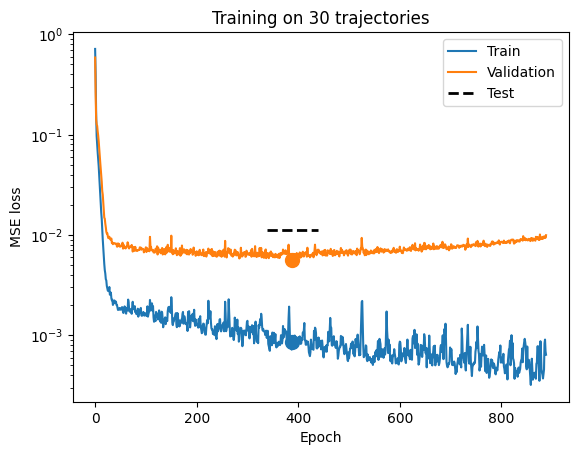

In [18]:
fig, ax = plt.subplots()
ax.plot(np.arange(len(small_t_loss)), small_t_loss, label='Train')
ax.plot(np.arange(len(small_v_loss)), small_v_loss, label='Validation')
best_epoch = small_early_stopping.best_epoch
ax.scatter(best_epoch, small_t_loss[best_epoch], s=100, c='C0',zorder=10)
ax.scatter(best_epoch, small_v_loss[best_epoch], s=100, c='C1',zorder=10)
ax.hlines(small_test_loss, xmin=best_epoch-50, xmax=best_epoch+50, color='k', label='Test', lw=2, ls='--')
ax.set_yscale('log')
ax.set_title('Training on 30 trajectories')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE loss')
ax.legend()

print(f'Best model results:\n \
        Train loss: {small_t_loss[best_epoch]}\n \
        Validation loss: {small_v_loss[best_epoch]}\n \
        Test loss: {small_test_loss}')

The training loss is much lower than the validation loss, indicating that the model is fitting the 30 trajectories without learning a sufficiently general description of the dynamics. We see that the model is overfitting when the validation loss starts increasing but the training loss keeps decreasing. 

### Roll-out of the model trained on 30 trajectories?

In [19]:
def rollout(model, trajectory):
	"""Predict a trajectory from its first three configurations ."""
	window = trajectory[:3]
	prediction = [r for r in window] # Remember these three configurations

	with torch.no_grad():
		for _ in range(3, len(trajectory)):
			x = window.reshape(1, 12)
			r_new = model(x)[0] # [0] ensures: shape change 1, 4 -> 4
			prediction.append(r_new)
			# Forget the oldest configuration and append the new one.
			window = torch.cat((window[1:] , r_new[None, :]), dim=0)
	return torch.stack(prediction)

trajectory = test_dataset.trajectories[0]
predicted_trajectory = rollout(small_model, trajectory)
predicted_trajectory.shape == trajectory.shape

True

In [20]:
def plot_predicted_traj(ax, prediction, title=None):
	ax.plot(prediction[:3, 0], prediction[:3, 1],
			c='white', marker='o', ms=4)
	ax.plot(prediction[3:, 0], prediction[3:, 1],
				c='C1', marker='o', ms=4)
	
	ax.plot(prediction[:3, 2], prediction[:3, 3],
			c='white', marker='o', ms=4)
	ax.plot(prediction[3:, 2], prediction[3:, 3],
				c='C1', marker='o', ms=4)
	
	if title is not None:
		ax.set_title(title)

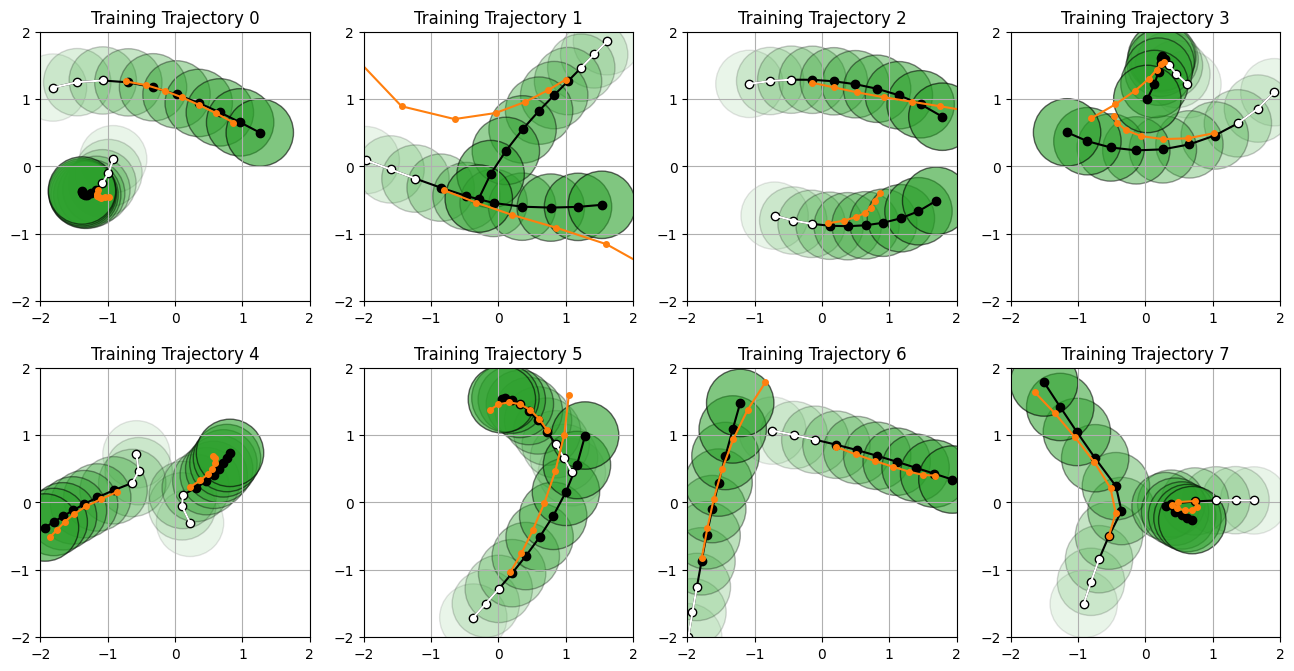

In [21]:
fig, axes = plt.subplots(2,4, figsize=(16,8))
for index, ax in enumerate(axes.flatten()):
	trajectory = train_dataset.trajectories[index]
	predicted_trajectory = rollout(small_model, trajectory)
	plot_traj(ax, train_traj, index)
	plot_predicted_traj(ax, predicted_trajectory, f'Training Trajectory {index}')

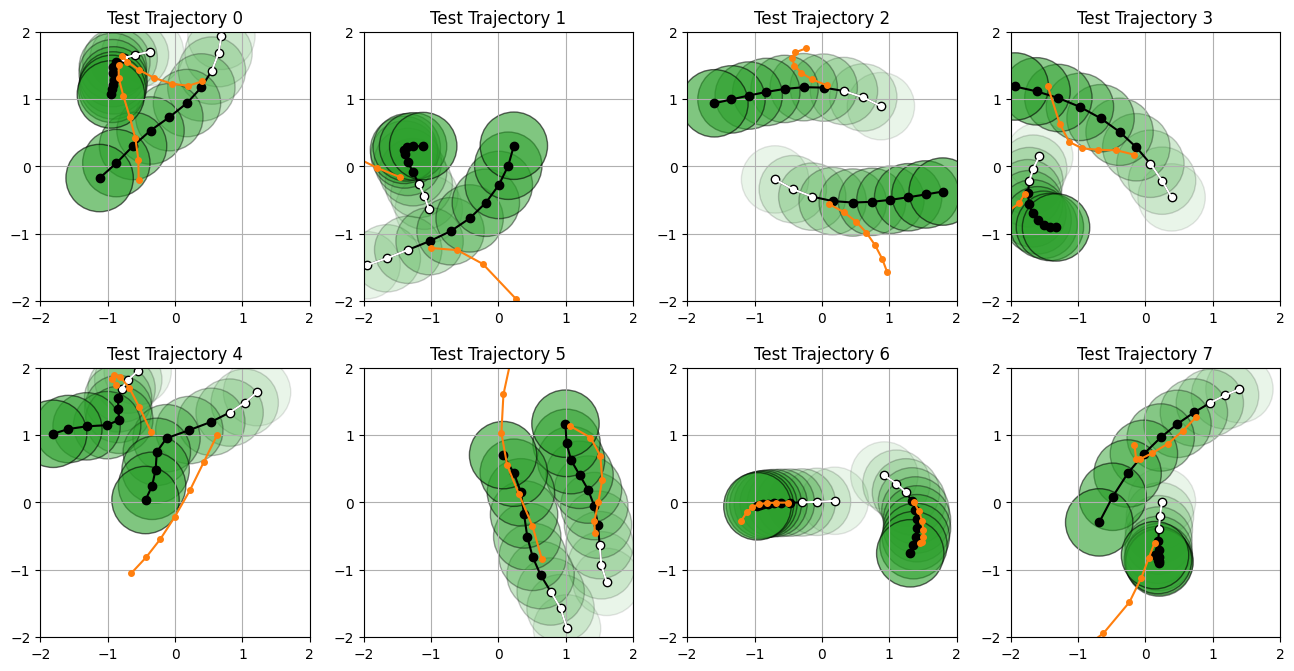

In [22]:
fig, axes = plt.subplots(2,4, figsize=(16,8))
for index, ax in enumerate(axes.flatten()):
	trajectory = test_dataset.trajectories[index]
	predicted_trajectory = rollout(small_model, trajectory)
	plot_traj(ax, test_traj, index)
	plot_predicted_traj(ax, predicted_trajectory, f'Test Trajectory {index}')

### Second attempt: 800 training trajectories

In [23]:
assert len(train_traj) == 800 #ensure there are 800 trajectories
large_model = OneStepTrajectoryNN()
large_early_stopping = EarlyStopping(patience = 500)  # different early stopping
large_t_loss, large_v_loss, large_test_loss = train_from_dataloader(large_model, 
                                       early_stopping=large_early_stopping, 
                                       train_loader=train_loader, # contains all 800 from previous cell
                                       val_loader=val_loader,
                                       test_loader=test_loader,
                                       epochs=5000)

Best model results:
         Train loss: 7.569618262225828e-06
         Validation loss: 8.9063816557809e-06
         Test loss: 1.1775503775502168e-05


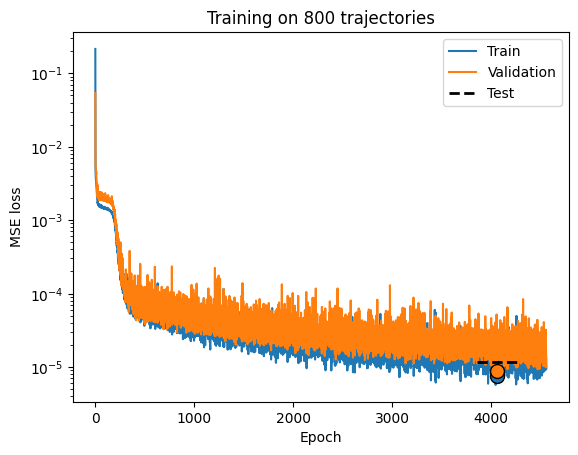

In [24]:
fig, ax = plt.subplots()
ax.plot(np.arange(len(large_t_loss)), large_t_loss, label='Train')
ax.plot(np.arange(len(large_v_loss)), large_v_loss, label='Validation')
best_epoch = large_early_stopping.best_epoch
ax.scatter(best_epoch, large_t_loss[best_epoch], s=100, c='C0',zorder=10, edgecolor='k')
ax.scatter(best_epoch, large_v_loss[best_epoch], s=100, c='C1',zorder=10, edgecolor='k')
ax.hlines(large_test_loss, xmin=best_epoch-200, xmax=best_epoch+200, color='k', label='Test', lw=2, ls='--')
ax.set_yscale('log')
ax.set_title('Training on 800 trajectories')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE loss')
ax.legend()

print(f'Best model results:\n \
        Train loss: {large_t_loss[best_epoch]}\n \
        Validation loss: {large_v_loss[best_epoch]}\n \
        Test loss: {large_test_loss}')

Patience of 500, epochs of 5000. Early stopping at around 4000 epochs. Took 14 minutes.

It seems the model could keep learning with a larger patience and more epochs. There are no indicationg of overfitting yet.

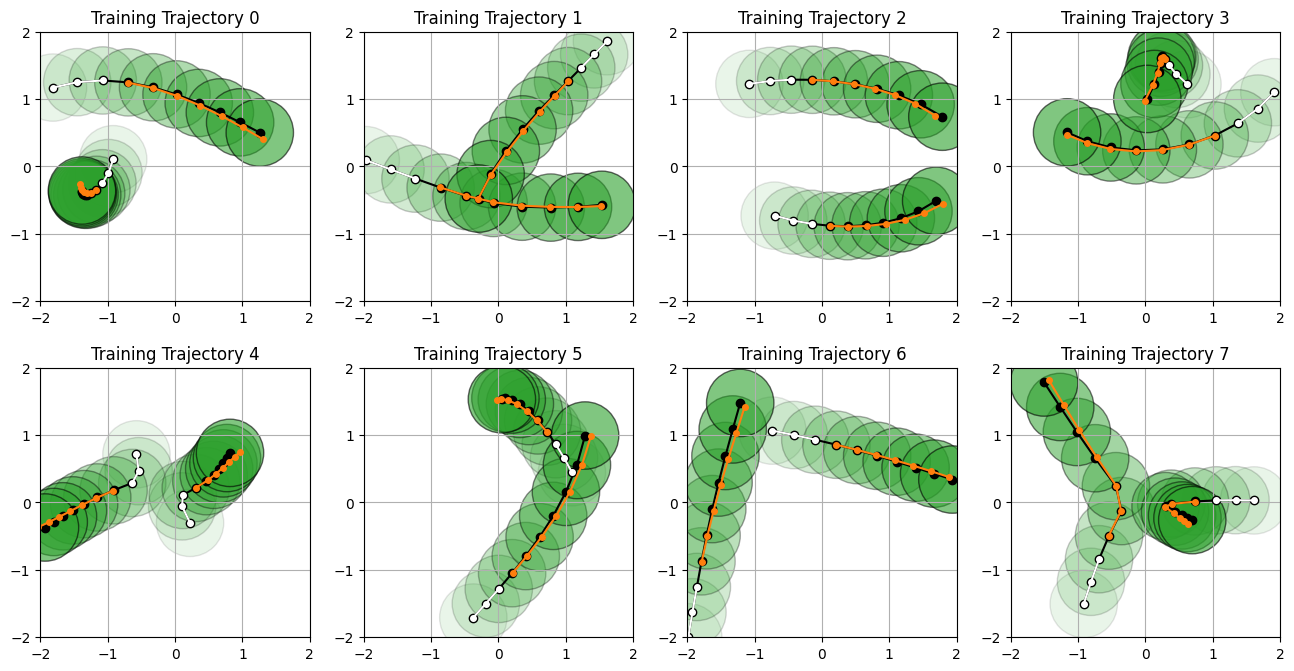

In [25]:
fig, axes = plt.subplots(2,4, figsize=(16,8))
for index, ax in enumerate(axes.flatten()):
	trajectory = train_dataset.trajectories[index]
	predicted_trajectory = rollout(large_model, trajectory)
	plot_traj(ax, train_traj, index)
	plot_predicted_traj(ax, predicted_trajectory, f'Training Trajectory {index}')

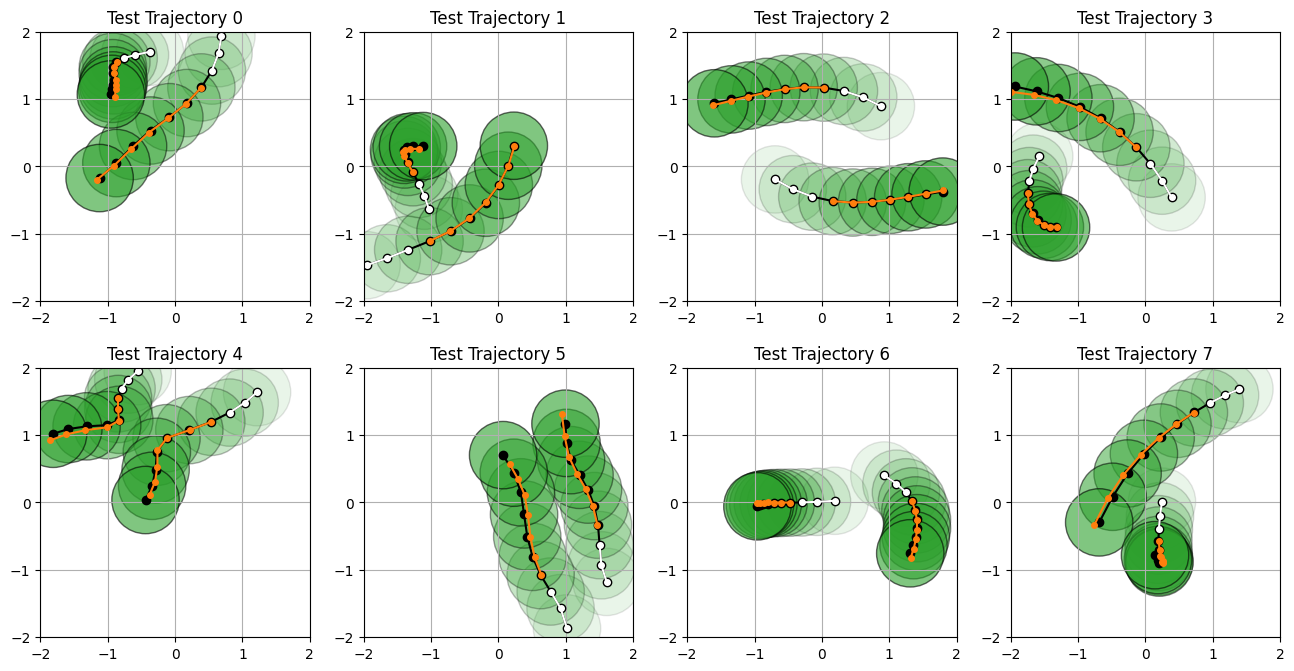

In [26]:
fig, axes = plt.subplots(2,4, figsize=(16,8))
for index, ax in enumerate(axes.flatten()):
	trajectory = test_dataset.trajectories[index]
	predicted_trajectory = rollout(large_model, trajectory)
	plot_traj(ax, test_traj, index)
	plot_predicted_traj(ax, predicted_trajectory, f'Test Trajectory {index}')

### Reflect

The gap between learning curves on 30 trajectories vs 800 trajectories decrease immensly. This indicates that with more training data, the model is able to form a generalized function in contrary to simply fitting the training data.

The one-step test loss (loss on test set) improves massively from 1e-2 to 3e-5.

Now there is much higher agreement between rollouts over training trajectories and test trajectories. The one-step loss between training and test is also more in agreement than before. This also indicates that the model is not fitting to the data (overfitting) but constructing a generalized function.

Predicting a long trajectory as opposed to one additional configuration is much more demanding of the model, since we rely on the models parameters being tuned well enough to predict on its previous prediction(s). If the model has some tiny error (about 3e-5) on every prediction, the last prediction on a long chain of predictions has accumulated to yield a much higher error. Thus the loss on predicting a single additional configuration must be near perfect to predict well on a long trajectory.'

<br>

To summarize, this comparison demonstrates the necessity of a relatively large and varied training set to be able to construct a generalizable model for a dynamical system.

# W11G A first differential equation

Solving

$\frac{dy}{dt}=0.9 y^2 \cos(t)$

The solution has the expression:

$y(t)=10y^{(0)} \cdot \left[10-9^{(0)}(\sin(t)-\sin(t^{(0)})\right]^{-1} $

In [25]:
import torch
import matplotlib.pyplot as plt

### The model with derivative

a) Write a Pytorch model that implements calculating a function and its derivative based on a
fully connected feed forward linear model with activation

In [26]:
class PINN(torch.nn.Module):  # PINN: Physics Informed NN
	def __init__(self, hidden_dim=8):
		super().__init__()
		self.net = torch.nn.Sequential(
			torch.nn.Linear(1, hidden_dim),
			torch.nn.SiLU(),
			torch.nn.Linear(hidden_dim, hidden_dim),
			torch.nn.SiLU(),
			torch.nn.Linear(hidden_dim, 1),
		)

	def forward(self, t):
		t = t.view(-1,1)
		return self.net(t)

	def prediction_and_derivative(self, t):
		prediction = self.forward(t)
		derivative = torch.autograd.grad(prediction, t, torch.ones_like(t), create_graph=True)[0]
		return prediction, derivative

### Loss function

In [27]:
def loss_fn(model, t0, y0, ti):
	sq_term = torch.mean((model(t0)-y0)**2) # using mean for future task
	ys_pred, dys_dt = model.prediction_and_derivative(ti)
	informed_term = torch.mean((dys_dt - 0.9*ys_pred**2 * torch.cos(ti))**2)
	return sq_term + informed_term

model = PINN()
tmax = 2; tmin = -2
ts_random = torch.rand((1000, 1), requires_grad=True) * (tmax-tmin) + tmin
loss_fn(model, torch.tensor(1.0), torch.tensor(1.0), ts_random)

tensor(0.9854, grad_fn=<AddBackward0>)

### Training

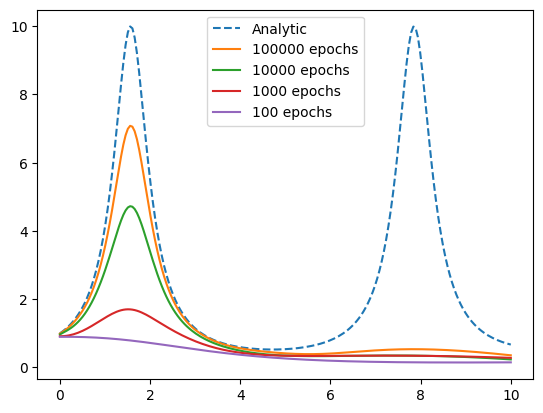

In [ ]:
def train_pinn(model, t0, y0, tmin, tmax, epochs=1000, lr=1e-3, weight_decay=0):
	optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
	for epoch in range(epochs):
		ts_rand = (torch.rand((100, 1)) * (tmax-tmin) + tmin).requires_grad_(True)
		loss = loss_fn(model, t0=t0, y0=y0, ti=ts_rand)
		optimizer.zero_grad()
		loss.backward()
		optimizer.step()
		# if (epoch+1) % 100 == 0 or epoch == 0:
		# 	print(f'{epoch if epoch==0 else epoch+1}: Loss =', train_loss)

t0 = torch.tensor(0.0); y0 = torch.tensor(1.0)
tmin = 0; tmax = 10
ts_lin = torch.linspace(0, 10, 200)
analytic = lambda t: 10*y0 * (10-9*y0*(torch.sin(t)-torch.sin(t0)))**(-1)

fig, ax = plt.subplots()
models = {}
ax.plot(ts_lin, analytic(ts_lin), ls='--', label='Analytic')
for epochs in reversed([100, 1_000, 10_000, 100_000]):
	model = PINN(hidden_dim=32)
	train_pinn(model, t0, y0, tmin, tmax, epochs=epochs, lr=1e-3)
	models[epochs] = model
	with torch.no_grad():
		ax.plot(ts_lin, model(ts_lin), label=f'{epochs} epochs')
ax.legend()


### More fix points

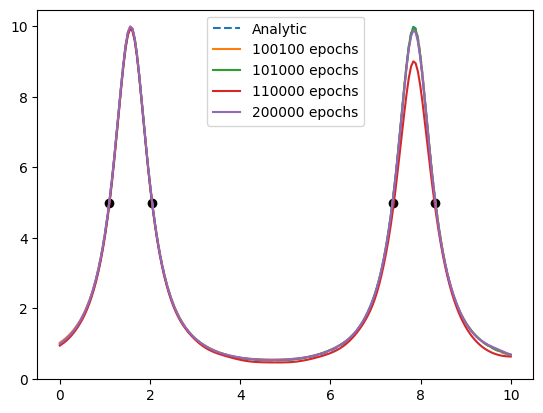

In [29]:
import copy

y0s = torch.tensor([5., 5, 5, 5])
t0s = torch.tensor([1.09491408, 2.04667858, 7.37809938, 8.32986388])

fig, ax = plt.subplots()
ax.plot(ts_lin, analytic(ts_lin), ls='--', label='Analytic')
for epochs in [100, 1_000, 10_000, 100_000]:
	model = copy.deepcopy(models[epochs])  # keep training on the same models
	train_pinn(model, t0s, y0s, tmin, tmax, epochs=100_000, lr=1e-3)
	with torch.no_grad():
		ax.plot(ts_lin, model(ts_lin), label=f'{epochs+100_000} epochs')
ax.scatter(t0s, y0s, color='k')
ax.legend()


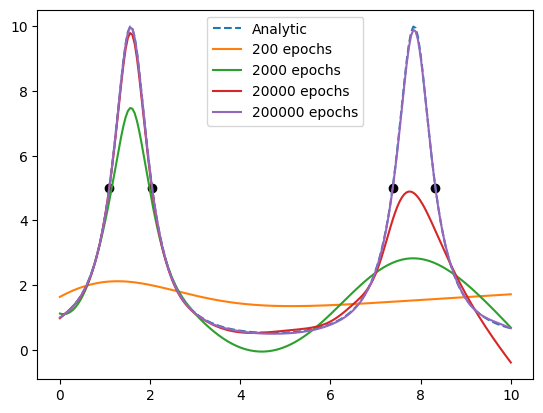

In [30]:
import copy

y0s = torch.tensor([5., 5, 5, 5])
t0s = torch.tensor([1.09491408, 2.04667858, 7.37809938, 8.32986388])

fig, ax = plt.subplots()
ax.plot(ts_lin, analytic(ts_lin), ls='--', label='Analytic')
for epochs in [100, 1_000, 10_000, 100_000]:
	model = copy.deepcopy(models[epochs])  # keep training on the same models
	train_pinn(model, t0s, y0s, tmin, tmax, epochs=epochs, lr=1e-3)
	with torch.no_grad():
		ax.plot(ts_lin, model(ts_lin), label=f'{2*epochs} epochs')
ax.scatter(t0s, y0s, color='k')
ax.legend()


# W11H Extrapolating radioactive decay with a physics-informed neural network

In [31]:
import torch
import matplotlib.pyplot as plt

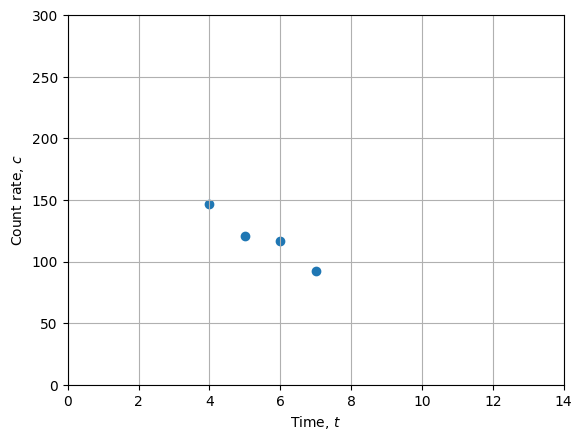

In [32]:
t = torch.tensor([4., 5, 6, 7])
c = torch.tensor([147., 121, 117, 92]) # count rate

fig, ax = plt.subplots()
ax.scatter(t, c)
ax.set_xlabel(r'Time, $t$')
ax.set_ylabel(r'Count rate, $c$')
ax.set_xlim(0, 14)
ax.set_ylim(0, 300)
ax.grid()

A flexible model made by e.g. a neural network could fit these points well but give any arbitrary value at $t=0$ depending on inital parameters. It could fit the points perfectly with a third degree polynomial, but it would be unphysical. We could use regularization and get something close to a linear function, but that would also be unphysical and yield an arbitrary value at $t=0$

In [33]:
class PINN(torch.nn.Module):  # PINN: Physics Informed NN
	def __init__(self, hidden_dim=8):
		super().__init__()
		self.net = torch.nn.Sequential(
			torch.nn.Linear(1, hidden_dim),
			torch.nn.SiLU(),
			torch.nn.Linear(hidden_dim, hidden_dim),
			torch.nn.SiLU(),
			torch.nn.Linear(hidden_dim, 1),
		)

	def forward(self, t):
		return self.net(t)
		
	def prediction_and_derivative(self, t):
		prediction = self.forward(t)
		derivative = torch.autograd.grad(prediction, t, torch.ones_like(t), create_graph=True)[0]
		return prediction, derivative

In [34]:
class PINNWithLambda(PINN):
	def __init__(self, lambd0, *args, **kwargs):
		super().__init__(*args, **kwargs)
		self.l = torch.nn.Parameter(data=self.inverse_softplus(lambd0))

	@property
	def lambd(self):
		return self.softplus(self.l)
	
	# y = softplus(x) = ln(1+exp(x))
	def softplus(self, x):
		return torch.log(1 + torch.exp(x))
	# solving for x:
	# x = ln(exp(y)-1)
	def inverse_softplus(self, x):
		assert x > 0, "x must be strictly positive"
		return torch.log(torch.expm1(x)) # expm1 = exp(x) - 1

def loss_fn(model, t, c, ti, w_physics):
	t = t.view(-1,1)
	c = c.view(-1,1)
	ti = ti.view(-1,1)
	loss_data = torch.mean((model(t)-c)**2)
	c_pred, dc_dt = model.prediction_and_derivative(ti)
	loss_physics = torch.mean((dc_dt + model.lambd*c_pred)**2)
	return loss_data + w_physics * loss_physics


###   Testing   ###
model = PINNWithLambda(lambd0=torch.tensor(0.1))
tmin = 0; tmax = 14
ti_random = torch.rand((100, 1), requires_grad=True) * (tmax-tmin) + tmin
loss_fn(model, t, c, ti_random, torch.tensor(1.))

tensor(14562.7588, grad_fn=<AddBackward0>)

In [35]:
def train_pinn(model, t, c, tmin, tmax, w_physics, epochs=1000, lr=1e-3, weight_decay=0):
	optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
	for epoch in range(epochs):
		ti_rand = (torch.rand((100, 1)) * (tmax-tmin) + tmin).requires_grad_(True)
		loss = loss_fn(model, t=t, c=c, ti=ti_rand, w_physics=w_physics)
		optimizer.zero_grad()
		loss.backward()
		optimizer.step()
		if (epoch+1) % 1000 == 0 or epoch == 0:
			print(f'{epoch if epoch==0 else epoch+1}: Loss =', loss.item())
	print(f'lambda = {model.lambd}')

0: Loss = 14518.9326171875
1000: Loss = 185.86773681640625
2000: Loss = 153.00921630859375
3000: Loss = 102.65348052978516
4000: Loss = 46.272300720214844
5000: Loss = 27.2713680267334
6000: Loss = 23.91997718811035
7000: Loss = 23.7061767578125
8000: Loss = 23.63292121887207
9000: Loss = 23.690980911254883
10000: Loss = 23.617250442504883
lambda = 0.14190052449703217


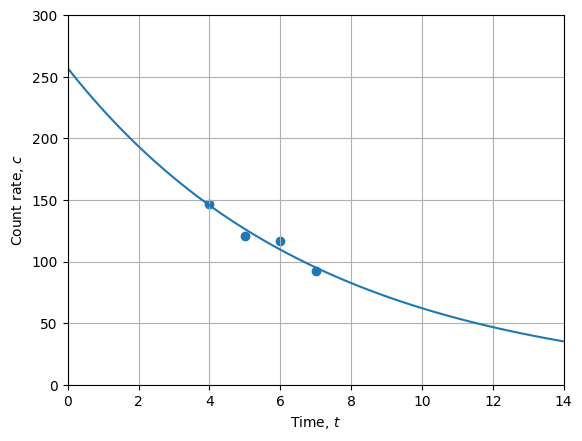

In [36]:
model = PINNWithLambda(hidden_dim=32, lambd0=torch.tensor(0.1))
train_pinn(model, t=t, c=c, tmin=0, tmax=14, w_physics=100, epochs=10_000)
fig, ax = plt.subplots()
t_lin = torch.linspace(0, 14, 100).view(-1,1)
with torch.no_grad():
	ax.plot(t_lin, model(t_lin))
ax.scatter(t, c)
ax.set_xlabel(r'Time, $t$')
ax.set_ylabel(r'Count rate, $c$')
ax.set_xlim(0, 14)
ax.set_ylim(0, 300)
ax.grid()

In [37]:
c0 = model(torch.tensor(0.0).view(-1,1)).item()
print(f'c(0) = {c0:.1f}')
print(f'lambda = {model.lambd:.4f}')

c(0) = 257.0
lambda = 0.1419


The fit reproduces the measured count rates quite nice, considering statistical error.

The differential equation is satisfied outside the range of the points, since it clearly follows the form of a radioactive decay.

If $w_{physics}$ is too small, the differential equation (the physical form of the fit) would not be very important for fitting the function, and the model would only care about fitting to the points. If $w_{physics}$ is too big, the measured points become irrelevant to the model predictions, and it would perhaps not fit them very well.

<br>

*Does a successful fit prove that the assumptions of a single isotope and negligible background radiation are correct?*

Not necessarily. With only 4 datapoints and statistical error, the fit cannot prove anything.

0: Loss = 14522.794921875
1000: Loss = 682.6640625
2000: Loss = 82.42855834960938
3000: Loss = 54.566776275634766
4000: Loss = 31.06538200378418
5000: Loss = 25.545846939086914
6000: Loss = 22.091777801513672
7000: Loss = 20.640615463256836
8000: Loss = 17.060497283935547
9000: Loss = 11.437952041625977
10000: Loss = 6.759068489074707
lambda = 0.15432678163051605


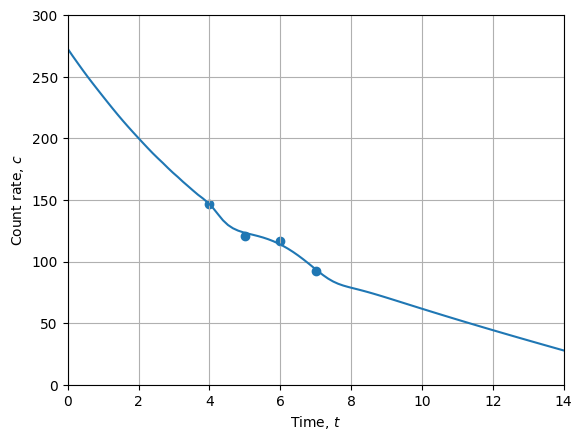

In [38]:
model = PINNWithLambda(hidden_dim=32, lambd0=torch.tensor(0.1))
train_pinn(model, t=t, c=c, tmin=0, tmax=14, w_physics=0.1, epochs=10_000)
fig, ax = plt.subplots()
t_lin = torch.linspace(0, 14, 100).view(-1,1)
with torch.no_grad():
	ax.plot(t_lin, model(t_lin))
ax.scatter(t, c)
ax.set_xlabel(r'Time, $t$')
ax.set_ylabel(r'Count rate, $c$')
ax.set_xlim(0, 14)
ax.set_ylim(0, 300)
ax.grid()

0: Loss = 14765.8193359375
1000: Loss = 203.62948608398438
2000: Loss = 184.0125732421875
3000: Loss = 163.47650146484375
4000: Loss = 145.37525939941406
5000: Loss = 128.95005798339844
6000: Loss = 111.66405487060547
7000: Loss = 98.92135620117188
8000: Loss = 85.4225082397461
9000: Loss = 77.95077514648438
10000: Loss = 66.09208679199219
lambda = 0.09265981614589691


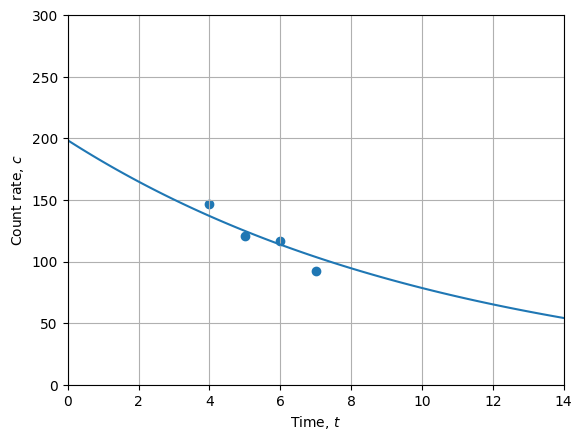

In [40]:
model = PINNWithLambda(hidden_dim=32, lambd0=torch.tensor(0.1))
train_pinn(model, t=t, c=c, tmin=0, tmax=14, w_physics=10_000, epochs=10_000)
fig, ax = plt.subplots()
t_lin = torch.linspace(0, 14, 100).view(-1,1)
with torch.no_grad():
	ax.plot(t_lin, model(t_lin))
ax.scatter(t, c)
ax.set_xlabel(r'Time, $t$')
ax.set_ylabel(r'Count rate, $c$')
ax.set_xlim(0, 14)
ax.set_ylim(0, 300)
ax.grid()

Takeaway from this exercise:

Let the NN handle the shapes as they are given, do not change shapes inside the network. Instead we pass the data as rank2 tensors, like:

X = torch.tensor([...], dtype=...).view(-1,1)

Implement optimizable parameters inside the neural network, not outside it. We can easily loose track of it, so keeping it inside is better.